# 1. Exploration et visualisation des données

## Objectif

Cette étape consiste à explorer et visualiser les données préparées dans les couches Silver et Gold du Data Lake Divvy.

L'objectif est de mettre en évidence les comportements des utilisateurs occasionnels et des abonnés, en étudiant notamment les dimensions temporelles, géographiques et les types de véhicules utilisés.

Les visualisations réalisées doivent permettre de répondre progressivement à la problématique du projet :

**Dans quelles stations et à quelles périodes concentrer les campagnes de conversion des utilisateurs occasionnels ?**

Une attention particulière sera portée au choix des représentations graphiques et à leur lisibilité. Une comparaison avant/après permettra également d'illustrer l'amélioration d'une visualisation à partir des principes de perception visuelle.

In [1]:
from commun.spark_utils import *

spark = creer_session("Divvy-Exploration")
spark.conf.set("spark.sql.session.timeZone", "America/Chicago")

print("Session Spark initialisée :", spark.version)

Préparation de Spark 4.2.0 (Hadoop 3.5.0) + Delta Lake + data lake S3 … le premier démarrage peut prendre quelques minutes.
Session prête. Spark UI : http://localhost:4040
Session Spark initialisée : 4.2.0


In [2]:
gold_station_period = spark.read.format("delta").load(f"{LAKE}/gold/station_period")
gold_monthly_overview = spark.read.format("delta").load(f"{LAKE}/gold/monthly_overview")
gold_station_ranking = spark.read.format("delta").load(f"{LAKE}/gold/station_ranking")

print("Gold station_period :", gold_station_period.count(), "lignes")
print("Gold monthly_overview :", gold_monthly_overview.count(), "lignes")
print("Gold station_ranking :", gold_station_ranking.count(), "lignes")

Gold station_period : 2334495 lignes
Gold monthly_overview : 100 lignes
Gold station_ranking : 1216 lignes


In [3]:
print("=== GOLD STATION PERIOD ===")
gold_station_period.printSchema()

print("\n=== GOLD MONTHLY OVERVIEW ===")
gold_monthly_overview.printSchema()

print("\n=== GOLD STATION RANKING ===")
gold_station_ranking.printSchema()

=== GOLD STATION PERIOD ===
root
 |-- start_station_id: string (nullable = true)
 |-- start_station_name: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- hour: integer (nullable = true)
 |-- rideable_type: string (nullable = true)
 |-- total_trips: long (nullable = true)
 |-- casual_trips: long (nullable = true)
 |-- member_trips: long (nullable = true)
 |-- casual_share_pct: double (nullable = true)


=== GOLD MONTHLY OVERVIEW ===
root
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- member_casual: string (nullable = true)
 |-- rideable_type: string (nullable = true)
 |-- total_trips: long (nullable = true)
 |-- avg_duration_seconds: double (nullable = true)
 |-- avg_duration_minutes: double (nullable = true)


=== GOLD STATION RANKING ===
root
 |-- start_station_id: string (nullable = true)
 |-- start_station_name: string (nullable = true)
 |-- total_tri

## 2. Exploration temporelle

Cette première exploration vise à étudier l'évolution mensuelle des trajets réalisés par les utilisateurs occasionnels (*casual*) et les abonnés (*member*) entre 2024 et 2025.

Elle permet d'identifier les variations saisonnières et les périodes durant lesquelles les utilisateurs occasionnels sont les plus actifs.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Conversion de la table Gold en DataFrame Pandas
df_monthly = gold_monthly_overview.toPandas()

# Création d'une colonne date pour faciliter le tri chronologique
df_monthly["date"] = pd.to_datetime(
    df_monthly["year"].astype(str) + "-" +
    df_monthly["month"].astype(str).str.zfill(2) + "-01"
)

# Agrégation des trajets par mois et catégorie d'utilisateur
df_temporal = (
    df_monthly
    .groupby(["date", "member_casual"], as_index=False)["total_trips"]
    .sum()
)

# Affichage des premières lignes
display(df_temporal.head())

,date,member_casual,total_trips
0,2024-01-01,casual,24365
1,2024-01-01,member,120260
2,2024-02-01,casual,47173
3,2024-02-01,member,176017
4,2024-03-01,casual,82479


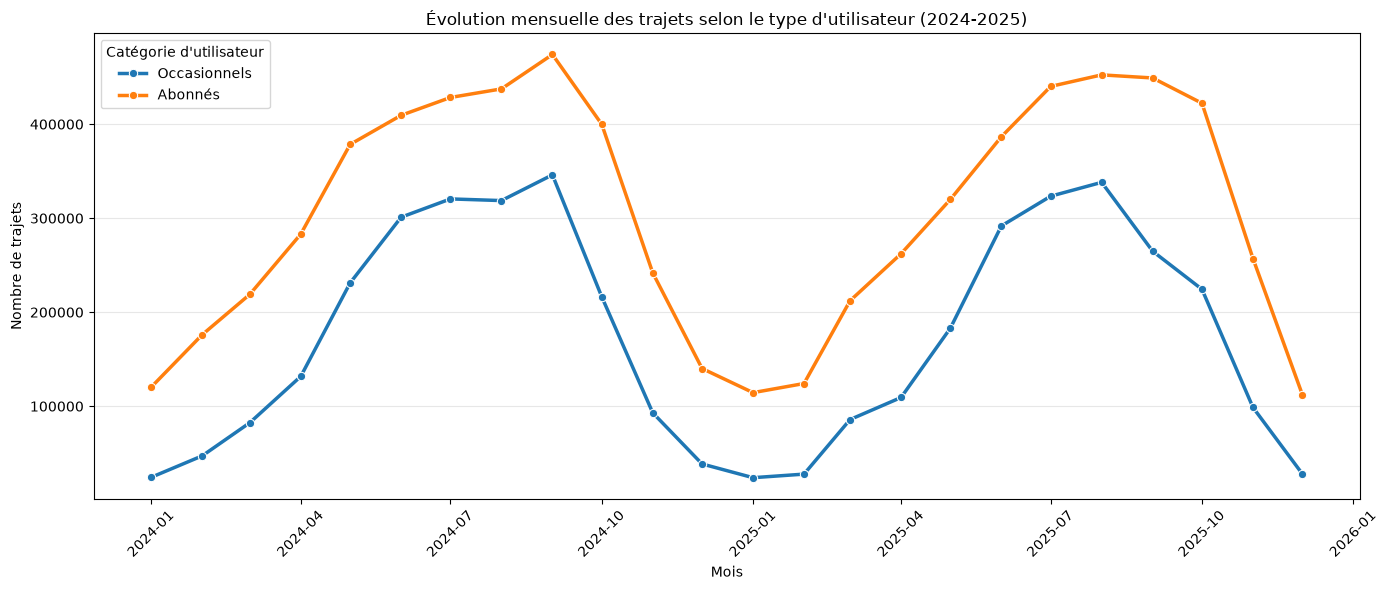

In [5]:
plt.figure(figsize=(14, 6))

# Traduction des catégories pour la légende
df_temporal["categorie"] = df_temporal["member_casual"].map({
    "casual": "Occasionnels",
    "member": "Abonnés"
})

sns.lineplot(
    data=df_temporal,
    x="date",
    y="total_trips",
    hue="categorie",
    hue_order=["Occasionnels", "Abonnés"],
    palette={
        "Occasionnels": "#1f77b4",
        "Abonnés": "#ff7f0e"
    },
    marker="o",
    linewidth=2.5,
    errorbar=None
)

plt.title("Évolution mensuelle des trajets selon le type d'utilisateur (2024-2025)")
plt.xlabel("Mois")
plt.ylabel("Nombre de trajets")
plt.legend(title="Catégorie d'utilisateur")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Analyse de l'évolution mensuelle

Le graphique met en évidence une saisonnalité importante de l'utilisation du service Divvy.

Les deux catégories d'utilisateurs présentent une évolution similaire : le nombre de trajets augmente progressivement au printemps, atteint son maximum pendant l'été, puis diminue fortement à l'approche de l'hiver.

Les utilisateurs occasionnels connaissent notamment leurs niveaux d'activité les plus élevés durant les mois de juillet et août. Cette période pourrait donc constituer une opportunité intéressante pour mener des campagnes de sensibilisation à l'abonnement annuel.

Les abonnés restent néanmoins majoritaires en volume de trajets sur l'ensemble des mois observés.

Cette première analyse montre que la saisonnalité constitue un facteur important à prendre en compte dans la définition des périodes de ciblage.

## 3. Exploration des stations

Cette partie vise à identifier les stations de départ les plus fréquentées par les utilisateurs occasionnels.

L'analyse s'appuie sur le nombre de trajets occasionnels réalisés dans chaque station sur la période 2024-2025. Elle permettra de repérer les emplacements présentant le plus fort potentiel de ciblage.

In [6]:
# Conversion de la table Gold en DataFrame Pandas
df_stations = gold_station_ranking.toPandas()

# Sélection des 10 stations ayant le plus de trajets occasionnels
top_10_stations = (
    df_stations
    .sort_values("casual_trips", ascending=False)
    .head(10)
)

display(
    top_10_stations[
        ["start_station_name", "total_trips", "casual_trips", "casual_share_pct"]
    ]
)

,start_station_name,total_trips,casual_trips,casual_share_pct
8,Streeter Dr & Grand Ave,77318,59513,76.97
7,DuSable Lake Shore Dr & Monroe St,52493,40829,77.78
36,Michigan Ave & Oak St,46293,28851,62.32
6,Navy Pier,35135,27414,78.02
22,Millennium Park,39537,26761,67.69
65,DuSable Lake Shore Dr & North Blvd,45359,26110,57.56
3,Shedd Aquarium,30976,25157,81.21
5,DuSable Lake Shore Dr & Monroe St,31105,24603,79.10
13,Dusable Harbor,30102,22128,73.51
70,Theater on the Lake,34373,19271,56.06


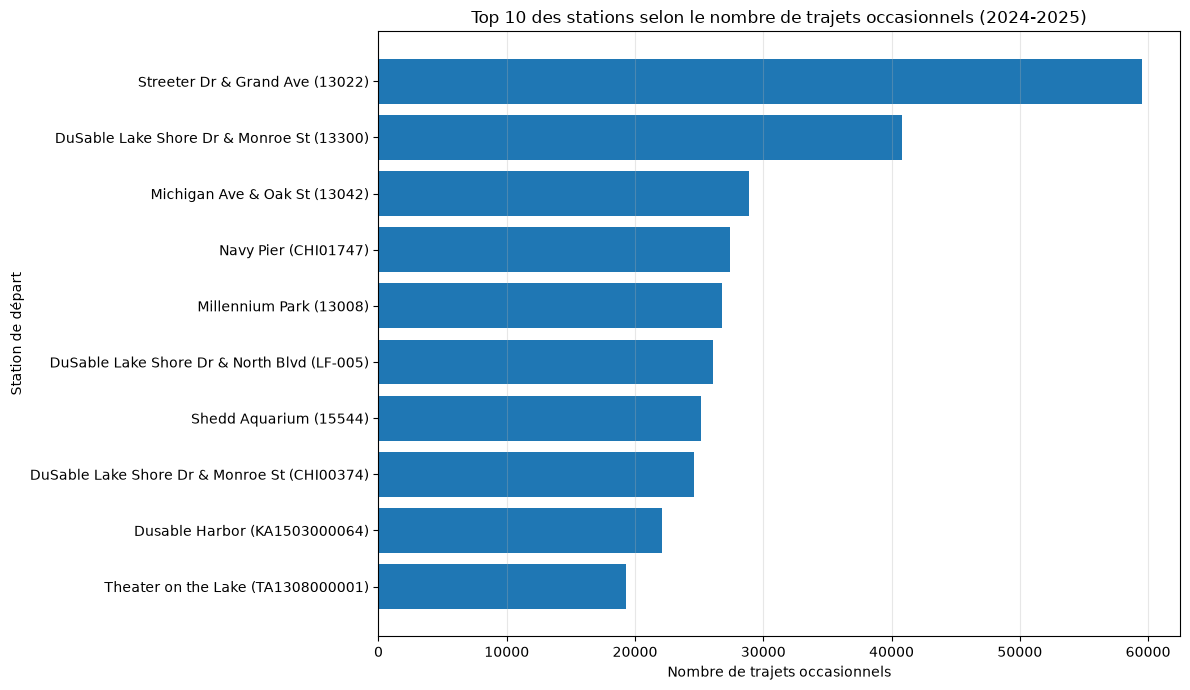

In [7]:
plt.figure(figsize=(12, 7))

df_plot = top_10_stations.copy()

# Ajouter l'identifiant pour distinguer les stations portant le même nom
df_plot["station_label"] = (
    df_plot["start_station_name"] + " (" +
    df_plot["start_station_id"] + ")"
)

df_plot = df_plot.sort_values("casual_trips", ascending=True)

plt.barh(
    df_plot["station_label"],
    df_plot["casual_trips"]
)

plt.title("Top 10 des stations selon le nombre de trajets occasionnels (2024-2025)")
plt.xlabel("Nombre de trajets occasionnels")
plt.ylabel("Station de départ")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

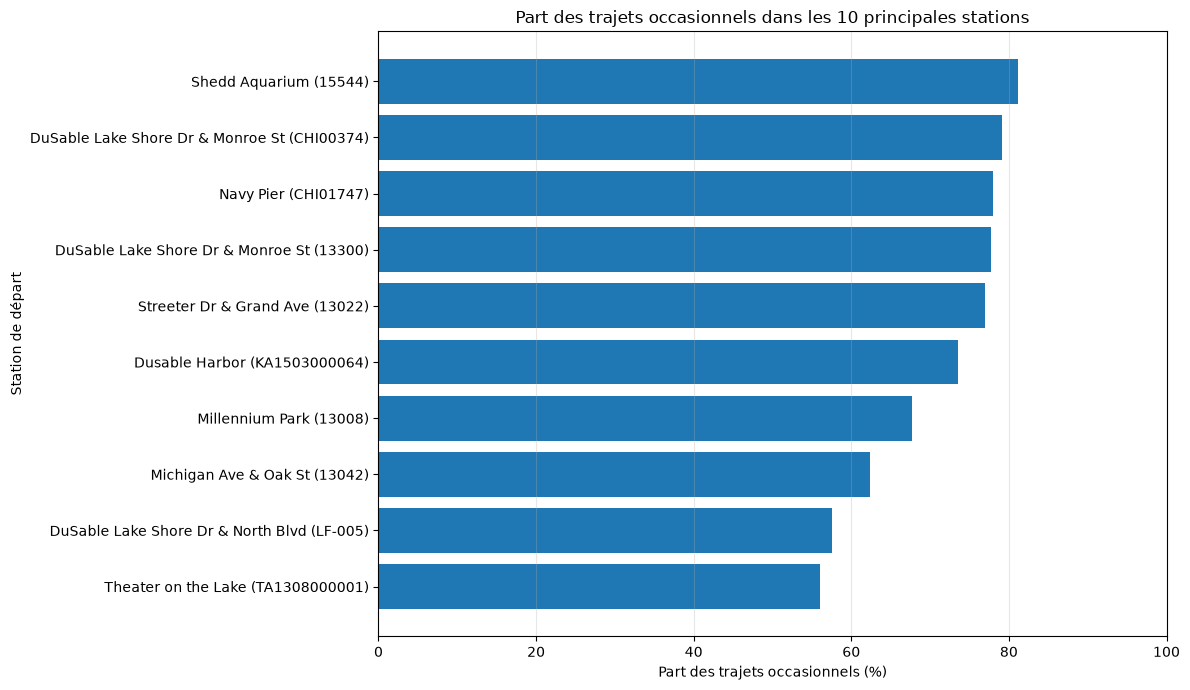

In [8]:
plt.figure(figsize=(12, 7))

df_plot = top_10_stations.copy()

df_plot["station_label"] = (
    df_plot["start_station_name"] + " (" +
    df_plot["start_station_id"] + ")"
)

df_plot = df_plot.sort_values("casual_share_pct", ascending=True)

plt.barh(
    df_plot["station_label"],
    df_plot["casual_share_pct"]
)

plt.title("Part des trajets occasionnels dans les 10 principales stations")
plt.xlabel("Part des trajets occasionnels (%)")
plt.ylabel("Station de départ")

plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Analyse de la fréquentation des stations

L'analyse des dix stations ayant enregistré le plus grand nombre de trajets occasionnels met en évidence une concentration importante de l'activité sur certains emplacements.

La station **Streeter Dr & Grand Ave** arrive largement en tête avec 59 513 trajets occasionnels sur la période 2024-2025. D'autres stations comme DuSable Lake Shore Dr & Monroe St, Michigan Ave & Oak St et Navy Pier présentent également des volumes importants.

La comparaison des volumes et des parts de trajets occasionnels apporte deux informations complémentaires :

- **Le volume de trajets occasionnels** permet d'identifier les stations qui concentrent le plus grand nombre d'utilisateurs occasionnels. Elles représentent des emplacements intéressants pour mener des campagnes de sensibilisation à l'abonnement.
- **La part de trajets occasionnels** permet d'identifier le poids de cette catégorie dans l'activité de chaque station. Parmi les dix stations étudiées, Shedd Aquarium présente la part la plus élevée avec 81,21 %.

Ces résultats montrent qu'une station très fréquentée n'est pas nécessairement celle qui possède la plus forte proportion d'utilisateurs occasionnels.

Il est donc pertinent de combiner ces deux indicateurs pour définir les emplacements prioritaires des futures campagnes de conversion.

## 4. Exploration des types de véhicules

Cette partie vise à étudier la répartition des trajets selon les types de véhicules utilisés, en distinguant les utilisateurs occasionnels des abonnés.

L'objectif est d'identifier les éventuelles différences de comportement entre les deux catégories d'utilisateurs et de déterminer quels types de véhicules concentrent le plus de trajets occasionnels.

L'analyse porte sur l'ensemble de la période 2024-2025.

In [9]:
# Agrégation des trajets par type de véhicule et catégorie d'utilisateur
df_vehicles = (
    df_monthly
    .groupby(["rideable_type", "member_casual"], as_index=False)["total_trips"]
    .sum()
)

display(df_vehicles)

,rideable_type,member_casual,total_trips
0,classic_bike,casual,1647497
1,classic_bike,member,3035928
2,electric_bike,casual,2417984
3,electric_bike,member,4166745
4,electric_scooter,casual,85215
5,electric_scooter,member,59122


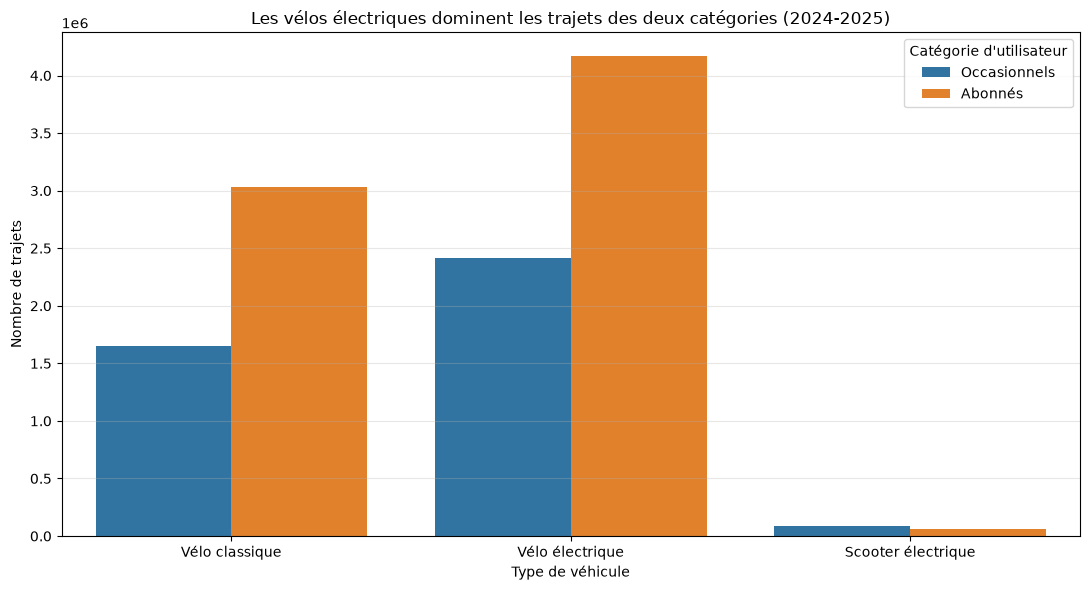

In [10]:
# Traduction des catégories pour améliorer la lisibilité
df_vehicles["vehicule"] = df_vehicles["rideable_type"].map({
    "classic_bike": "Vélo classique",
    "electric_bike": "Vélo électrique",
    "electric_scooter": "Scooter électrique"
})

df_vehicles["categorie"] = df_vehicles["member_casual"].map({
    "casual": "Occasionnels",
    "member": "Abonnés"
})

plt.figure(figsize=(11, 6))

sns.barplot(
    data=df_vehicles,
    x="vehicule",
    y="total_trips",
    hue="categorie",
    hue_order=["Occasionnels", "Abonnés"],
    palette={
        "Occasionnels": "#1f77b4",
        "Abonnés": "#ff7f0e"
    },
    errorbar=None
)

plt.title("Les vélos électriques dominent les trajets des deux catégories (2024-2025)")
plt.xlabel("Type de véhicule")
plt.ylabel("Nombre de trajets")
plt.legend(title="Catégorie d'utilisateur")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Analyse de la répartition des trajets par type de véhicule

La comparaison des types de véhicules met en évidence plusieurs différences entre les utilisateurs occasionnels et les abonnés.

Le **vélo électrique** est le véhicule le plus utilisé dans les deux catégories, avec respectivement 2 417 984 trajets occasionnels et 4 166 745 trajets abonnés.

Les vélos classiques occupent également une place importante, avec un volume de trajets plus élevé chez les abonnés.

Une différence apparaît toutefois concernant les scooters électriques : les utilisateurs occasionnels réalisent 85 215 trajets, contre 59 122 pour les abonnés. Il s'agit du seul type de véhicule pour lequel les trajets occasionnels sont majoritaires.

Ces résultats montrent que les véhicules électriques occupent une place importante dans les habitudes des utilisateurs. Ils suggèrent également que les scooters électriques présentent un comportement d'utilisation différent des vélos, ce qui pourrait constituer une piste complémentaire pour adapter les futures campagnes de sensibilisation à l'abonnement.

## 5. Comparaison avant / après : amélioration d'une visualisation

Cette partie présente une comparaison entre une visualisation volontairement inadaptée et une version corrigée.

L'objectif est de montrer comment certains choix graphiques peuvent nuire à la compréhension des données et comment les principes de perception visuelle permettent d'améliorer leur lisibilité.

L'exemple retenu porte sur les dix stations ayant enregistré le plus grand nombre de trajets occasionnels entre 2024 et 2025.

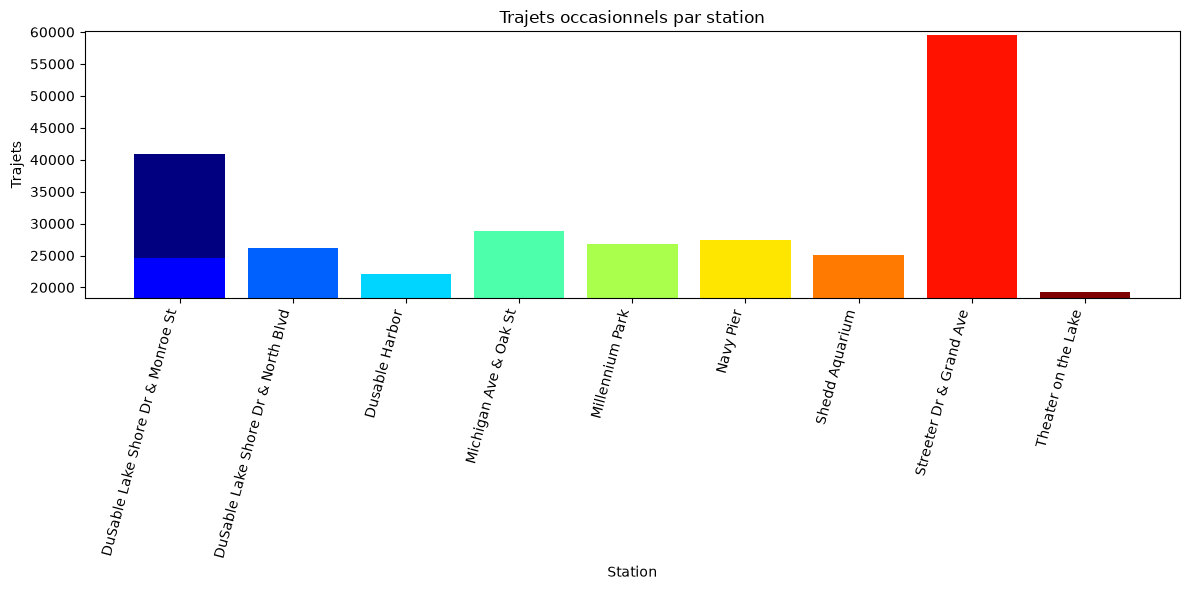

In [11]:
# Graphique volontairement peu lisible : version naïve

import numpy as np
df_naif = top_10_stations.sort_values("start_station_name")

plt.figure(figsize=(12, 6))

couleurs = plt.cm.jet(
    np.linspace(0, 1, len(df_naif))
)

plt.bar(
    df_naif["start_station_name"],
    df_naif["casual_trips"],
    color=couleurs
)

plt.title("Trajets occasionnels par station")
plt.xlabel("Station")
plt.ylabel("Trajets")

# Axe vertical volontairement tronqué
plt.ylim(
    df_naif["casual_trips"].min() * 0.95,
    df_naif["casual_trips"].max() * 1.01
)

plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

### Analyse des défauts de la visualisation initiale

La première visualisation présente plusieurs choix graphiques qui nuisent à la compréhension des données.

- **Palette de couleurs :** l'utilisation d'une palette arc-en-ciel attribue une couleur différente à chaque station, sans signification particulière. Cela ajoute du bruit visuel.
- **Ordre des catégories :** les stations ne sont pas classées selon leur nombre de trajets occasionnels. La comparaison des valeurs est donc moins intuitive.
- **Orientation :** les barres verticales et les noms de stations inclinés rendent la lecture des catégories moins confortable.
- **Titre :** le titre est trop général et ne précise ni le classement ni la période étudiée.
- **Échelle :** l'axe vertical est tronqué et ne commence pas à zéro. Cela accentue artificiellement les différences entre les valeurs.

Ces défauts rendent la comparaison moins précise, notamment parce que les valeurs sont plus difficiles à comparer sur une échelle commune.

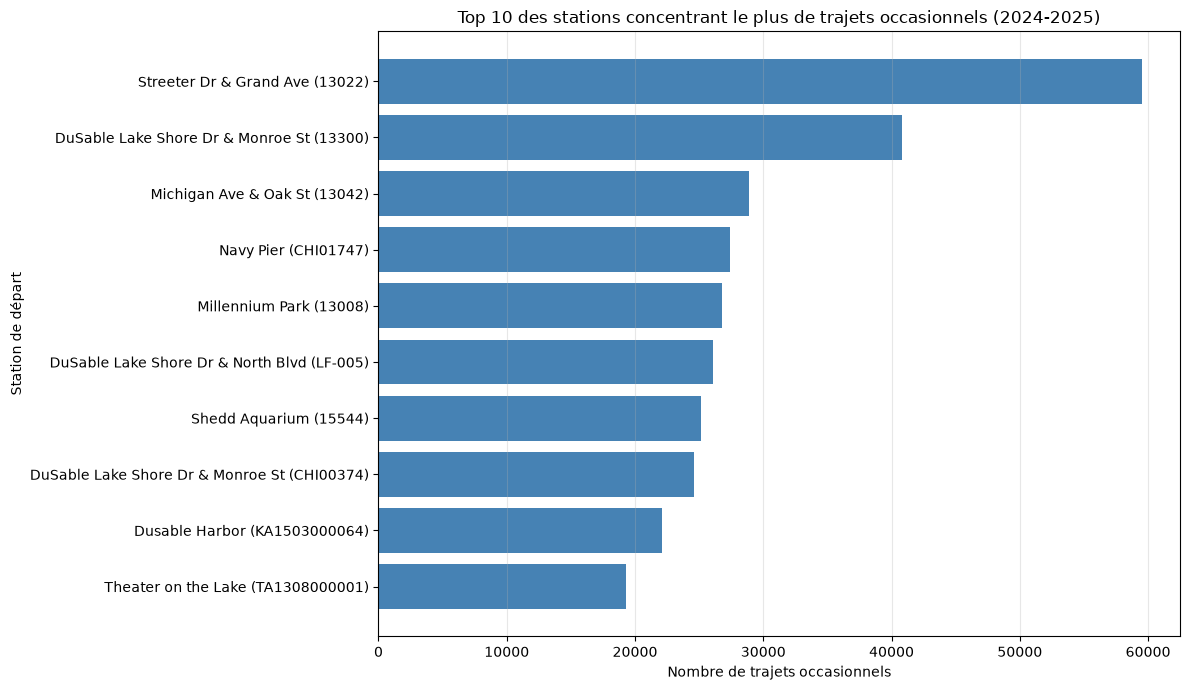

In [12]:
# Graphique corrigé : classement des 10 stations

df_corrige = top_10_stations.copy()

df_corrige["station_label"] = (
    df_corrige["start_station_name"]
    + " (" + df_corrige["start_station_id"] + ")"
)

df_corrige = df_corrige.sort_values(
    "casual_trips", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    df_corrige["station_label"],
    df_corrige["casual_trips"],
    color="steelblue"
)

plt.title(
    "Top 10 des stations concentrant le plus de trajets occasionnels (2024-2025)"
)
plt.xlabel("Nombre de trajets occasionnels")
plt.ylabel("Station de départ")

# L'axe commence à zéro
plt.xlim(left=0)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Justification des améliorations apportées

La seconde visualisation corrige les défauts identifiés précédemment en s'appuyant sur les principes de perception visuelle étudiés en cours.

- **Barres horizontales :** elles facilitent la lecture des noms de stations, notamment lorsque ceux-ci sont longs.
- **Classement des valeurs :** les stations sont triées selon le nombre de trajets occasionnels. La comparaison devient plus intuitive et les stations prioritaires ressortent immédiatement.
- **Couleur unique :** une seule couleur est utilisée, car les catégories ne nécessitent pas de distinction visuelle supplémentaire.
- **Échelle adaptée :** l'axe commence à zéro, ce qui permet de représenter les différences de volume sans les exagérer.
- **Titre et unités :** le titre précise l'indicateur étudié et la période concernée, tandis que l'axe horizontal indique clairement le nombre de trajets.

Ce choix de représentation s'appuie notamment sur les travaux de Cleveland et McGill (1984) : la comparaison de positions sur une échelle commune est plus précise que la comparaison de surfaces ou de couleurs.

La visualisation corrigée permet ainsi d'identifier rapidement les stations concentrant le plus de trajets occasionnels et facilite leur comparaison.

## 6. Synthèse de l'exploration

L'exploration des données Divvy sur la période 2024-2025 fait ressortir plusieurs éléments utiles pour orienter les campagnes de conversion des utilisateurs occasionnels.

**Périodes de ciblage**

L'activité des utilisateurs occasionnels augmente fortement au printemps et atteint ses niveaux les plus élevés pendant l'été, notamment en juillet et août. Ces périodes semblent donc particulièrement intéressantes pour concentrer les campagnes.

**Stations prioritaires**

Certaines stations présentent un volume important de trajets occasionnels. Streeter Dr & Grand Ave arrive en tête avec 59 513 trajets occasionnels. D'autres stations situées à proximité de lieux touristiques, comme Navy Pier et Shedd Aquarium, présentent également un potentiel intéressant.

**Types de véhicules**

Les vélos électriques représentent le type de véhicule le plus utilisé par les deux catégories d'utilisateurs. Les scooters électriques constituent toutefois un cas particulier : les trajets occasionnels y sont plus nombreux que ceux des abonnés.

**Conclusion**

Les résultats suggèrent de privilégier les campagnes pendant la période estivale et de les concentrer dans les stations présentant un volume élevé de trajets occasionnels. Le type de véhicule utilisé peut également permettre d'adapter les messages de communication.

Ces observations constituent une première base d'aide à la décision pour répondre à la problématique du projet.